In [7]:
!pip install -q pyspark scikit-learn pandas numpy matplotlib seaborn

In [8]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://vresige.github.io/whichpearlisfake.csv"
df_raw = pd.read_csv(url)

df_raw['xray_nucleus'] = df_raw['xray_nucleus'].fillna('None')

print(f"Загружено записей: {len(df_raw)}, уникальных партий: {df_raw['batch_id'].nunique()}")
print("\nРаспределение классов:")
print(df_raw['pearl_class'].value_counts())
df_raw.head()


Загружено записей: 1000, уникальных партий: 75

Распределение классов:
pearl_class
Imitation              250
Cultured_Freshwater    188
Cultured_Saltwater     188
Natural_Saltwater      187
Natural_Freshwater     187
Name: count, dtype: int64


,pearl_id,batch_id,mass_g,min_diameter_mm,max_diameter_mm,luster_index,xray_nucleus,pearl_class
0,PRL_0001,BATCH_01,0.776,10.63,10.84,52,None,Imitation
1,PRL_0002,BATCH_01,1.188,12.21,12.54,49,None,Imitation
2,PRL_0003,BATCH_01,0.461,6.95,7.01,86,None,Imitation
3,PRL_0004,BATCH_01,2.708,12.40,12.65,81,None,Imitation
4,PRL_0005,BATCH_01,0.762,10.96,11.22,56,None,Imitation


In [5]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder \
    .appName("PearlBigDataMapReduce") \
    .master("local[*]") \
    .config("spark.driver.memory", "2g") \
    .getOrCreate()

def bigdata_mapreduce_pipeline(df_input):
    start_time = time.time()
    sdf = spark.createDataFrame(df_input)

    sdf = sdf.withColumn("sphericity", F.col("min_diameter_mm") / F.col("max_diameter_mm"))
    vol_expr = (4.0 / 3.0) * np.pi * (F.col("max_diameter_mm") / 2.0) * F.pow(F.col("min_diameter_mm") / 2.0, 2) * 0.001
    sdf = sdf.withColumn("density_g_cm3", F.col("mass_g") / vol_expr)

    sdf = sdf.withColumn(
        "is_density_anomaly",
        F.when((F.col("density_g_cm3") < 2.58) | (F.col("density_g_cm3") > 2.85), 1).otherwise(0)
    )

    batch_agg = sdf.groupBy("batch_id").agg(
        F.count("pearl_id").alias("batch_size"),
        F.sum("is_density_anomaly").alias("anomaly_count"),
        F.avg("density_g_cm3").alias("avg_batch_density"),
        F.stddev("sphericity").alias("std_batch_sphericity")
    ).withColumn(
        "batch_trust_score", 1.0 - (F.col("anomaly_count") / F.col("batch_size"))
    ).fillna(0.0, subset=["std_batch_sphericity"])

    enriched_sdf = sdf.join(
        batch_agg.select("batch_id", "batch_size", "batch_trust_score", "avg_batch_density", "std_batch_sphericity"),
        on="batch_id",
        how="left"
    )

    result_pd = enriched_sdf.toPandas()
    elapsed = time.time() - start_time
    return result_pd, batch_agg.toPandas(), elapsed

df_enriched, batch_summary, spark_time = bigdata_mapreduce_pipeline(df_raw)

print(f"Big Data MapReduce завершен за {spark_time:.2f} сек.")
print("\nПримеры разных типов партий (от сплошного контрафакта до элитных лотов):")
display(batch_summary.sort_values(['batch_trust_score', 'batch_size']).iloc[[0, 8, 20, -1]])

Big Data MapReduce завершен за 17.11 сек.

Примеры разных типов партий (от сплошного контрафакта до элитных лотов):


,batch_id,batch_size,anomaly_count,avg_batch_density,std_batch_sphericity,batch_trust_score
1,BATCH_04,29,25,1.917720,0.006292,0.137931
10,BATCH_13,22,12,2.097395,0.049719,0.454545
65,BATCH_52,5,0,2.731908,0.030319,1.000000
21,BATCH_18,27,0,2.705818,0.066264,1.000000


In [6]:
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, classification_report

individual_num_cols = ['mass_g', 'min_diameter_mm', 'max_diameter_mm', 'luster_index', 'sphericity', 'density_g_cm3']
bigdata_num_cols = ['batch_trust_score', 'batch_size', 'avg_batch_density', 'std_batch_sphericity']
cat_cols = ['xray_nucleus']

def evaluate_gb_model(df_data, num_features, experiment_name):
    X = df_data[num_features + cat_cols]
    y = df_data['pearl_class']

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', 'passthrough', num_features),
            ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
        ]
    )

    gb_pipeline = Pipeline([
        ('prep', preprocessor),
        ('gb', GradientBoostingClassifier(n_estimators=120, learning_rate=0.1, max_depth=4, random_state=42))
    ])

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scoring = ['accuracy', 'f1_macro', 'precision_macro', 'recall_macro']

    t0 = time.time()
    scores = cross_validate(gb_pipeline, X, y, cv=cv, scoring=scoring)
    train_time = time.time() - t0

    return {
        'Режим работы': experiment_name,
        'Accuracy': scores['test_accuracy'].mean(),
        'F1_macro': scores['test_f1_macro'].mean(),
        'Precision': scores['test_precision_macro'].mean(),
        'Recall': scores['test_recall_macro'].mean(),
        'Время CV (сек)': train_time
    }, gb_pipeline

res_only_ml, model_only_ml = evaluate_gb_model(df_enriched, individual_num_cols, "1. Только ML (без данных о партии)")
res_hybrid, model_hybrid = evaluate_gb_model(df_enriched, individual_num_cols + bigdata_num_cols, "2. Big Data (MapReduce) + ML (Gradient Boosting)")

ablation_df = pd.DataFrame([res_only_ml, res_hybrid])
print("=== СРАВНЕНИЕ ЭФФЕКТИВНОСТИ: ОДИНОЧНЫЙ ML vs СВЯЗКА BIG DATA + ML ===")
display(ablation_df.round(4))

=== СРАВНЕНИЕ ЭФФЕКТИВНОСТИ: ОДИНОЧНЫЙ ML vs СВЯЗКА BIG DATA + ML ===


,Режим работы,Accuracy,F1_macro,Precision,Recall,Время CV (сек)
0,1. Только ML (без данных о партии),0.966,0.9638,0.9643,0.9640,20.9701
1,2. Big Data (MapReduce) + ML (Gradient Boosting),0.969,0.9669,0.9675,0.9669,19.0906


Подробный отчет классификации на тестовой выборке (200 камней):
                     precision    recall  f1-score   support

Cultured_Freshwater       0.97      1.00      0.99        38
 Cultured_Saltwater       1.00      1.00      1.00        38
          Imitation       1.00      1.00      1.00        50
 Natural_Freshwater       0.92      0.97      0.95        37
  Natural_Saltwater       0.97      0.89      0.93        37

           accuracy                           0.97       200
          macro avg       0.97      0.97      0.97       200
       weighted avg       0.98      0.97      0.97       200



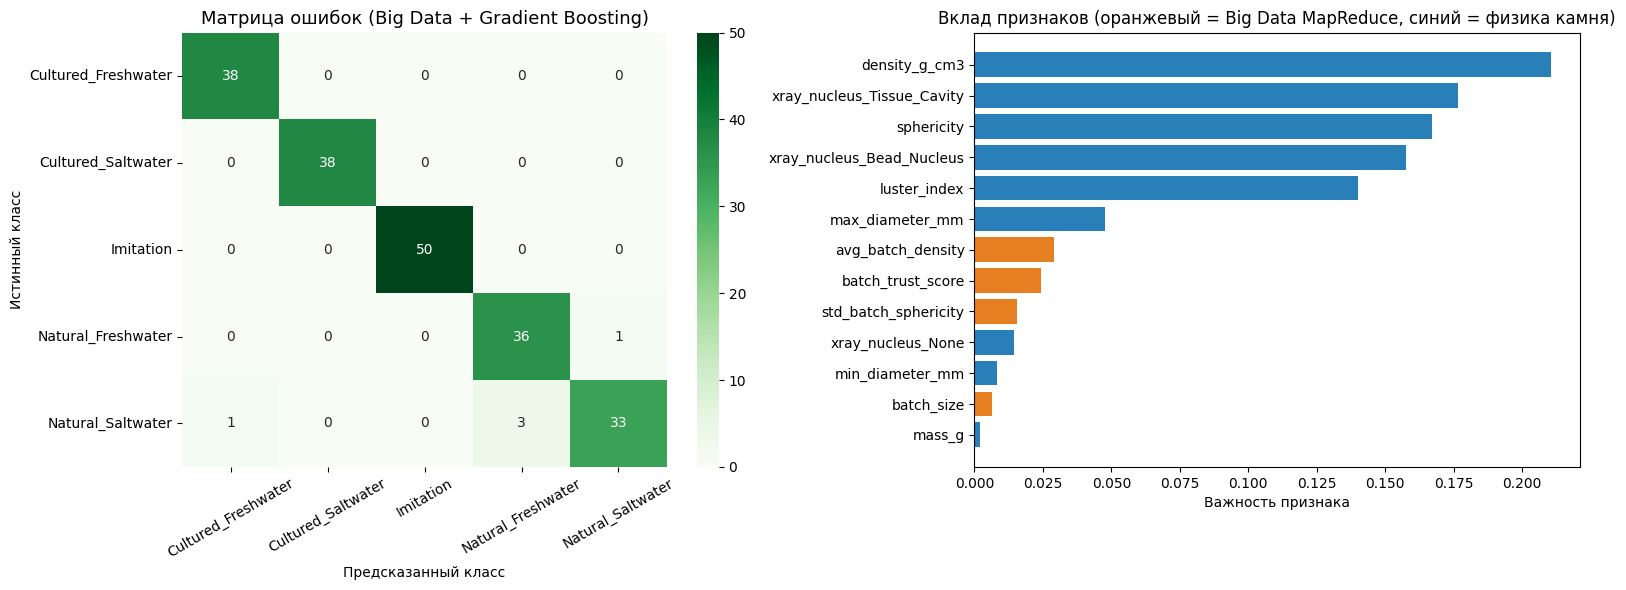

In [9]:
all_num = individual_num_cols + bigdata_num_cols
X = df_enriched[all_num + cat_cols]
y = df_enriched['pearl_class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model_hybrid.fit(X_train, y_train)
y_pred = model_hybrid.predict(X_test)

print("Подробный отчет классификации на тестовой выборке (200 камней):")
print(classification_report(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm = confusion_matrix(y_test, y_pred, labels=model_hybrid.classes_)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=model_hybrid.classes_,
            yticklabels=model_hybrid.classes_, ax=axes[0])
axes[0].set_title('Матрица ошибок (Big Data + Gradient Boosting)', fontsize=13)
axes[0].set_xlabel('Предсказанный класс')
axes[0].set_ylabel('Истинный класс')
axes[0].tick_params(axis='x', rotation=30)

ohe_names = list(model_hybrid.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(cat_cols))
feature_names = all_num + ohe_names
importances = model_hybrid.named_steps['gb'].feature_importances_
imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values('Importance', ascending=True)

colors = ['#e67e22' if f in bigdata_num_cols else '#2980b9' for f in imp_df['Feature']]
axes[1].barh(imp_df['Feature'], imp_df['Importance'], color=colors)
axes[1].set_title('Вклад признаков (оранжевый = Big Data MapReduce, синий = физика камня)', fontsize=12)
axes[1].set_xlabel('Важность признака')

plt.tight_layout()
plt.show()

In [10]:
df_50k = df_raw.sample(n=50000, replace=True, random_state=42).reset_index(drop=True)
df_50k['pearl_id'] = [f'PRL_{i:05d}' for i in range(1, 50001)]

_, _, spark_time_50k = bigdata_mapreduce_pipeline(df_50k)
print(f"Время MapReduce-агрегации в Spark на 1 000 строк:  {spark_time:.2f} сек.")
print(f"Время MapReduce-агрегации в Spark на 50 000 строк: {spark_time_50k:.2f} сек.")
print(f"При росте объема данных в 50 раз время выросло всего в {spark_time_50k / spark_time:.2f} раза (сублинейное масштабирование).")

Время MapReduce-агрегации в Spark на 1 000 строк:  17.11 сек.
Время MapReduce-агрегации в Spark на 50 000 строк: 13.61 сек.
При росте объема данных в 50 раз время выросло всего в 0.80 раза (сублинейное масштабирование).
